# Saudi Student Dropout Prediction — CS316 Project
Dataset: Saudi Student Dropout Dataset (PeerJ, 2026)

Run Step 1 to Step 12 in order.
The test set is kept untouched until the final evaluation.


## Step 1 — Install packages and load the CSV


In [1]:
!pip -q install imbalanced-learn

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from google.colab import files

uploaded = files.upload()
filename = next(iter(uploaded))

df = pd.read_csv(filename)

# Clean column names
df.columns = df.columns.astype(str).str.strip()

print("Dataset shape:", df.shape)
display(df.head())
print("\nColumns:")
print(df.columns.tolist())


Saving Saudi_Student_Dropout_Data (1).csv to Saudi_Student_Dropout_Data (1).csv
Dataset shape: (4560, 26)


,Dropout,Gender,Age,Employment Status,Marital Status,Year,University Name,Faculty Name,Program Type,GPA,...,Major Preknowledge,Peer Influence,Family/Employer Pressure,Cultural Expectation,City Moving,Commitments,Living Expenses,Family/Friends Support,Psychological Issues,Health Issues
0,Yes,Female,18 - 25,Unemployed,Single,First Year,JIC,Preparatory year,Free Bachelor,Excellent,...,Yes,Yes,No,No,No,Yes,No,Yes,Yes,Yes
1,No,Female,26 - 33,Unemployed,Single,Above Third Year,KAU,College of CS and IT,Free Master's,Excellent,...,Yes,Yes,No,No,No,Yes,Yes,Yes,Yes,Yes
2,No,Female,26 - 33,Unemployed,Single,First Year,KAU,College of CS and IT,Free Master's,GPA is not showing yet,...,No,No,No,No,No,No,No,Yes,Yes,No
3,No,Female,18 - 25,Unemployed,Single,Graduated,KAU,College of Communication and Media,Free Bachelor,Excellent,...,Yes,No,No,No,No,No,No,No,No,No
4,Yes,Female,18 - 25,Employed full-time,Married,Third Year,KAU,College of CS and IT,Free Master's,Very Good,...,Yes,No,Yes,Yes,No,Yes,Yes,No,Yes,No



Columns:
['Dropout', 'Gender', 'Age', 'Employment Status', 'Marital Status', 'Year', 'University Name', 'Faculty Name', 'Program Type', 'GPA', 'Failed Courses', 'Academic Warnings', 'Studying Difficulty', 'University Satisfaction', 'English Language', 'Language Barrier', 'Major Preknowledge', 'Peer Influence', 'Family/Employer Pressure', 'Cultural Expectation', 'City Moving', 'Commitments', 'Living Expenses', 'Family/Friends Support', 'Psychological Issues', 'Health Issues']


## Step 2 — Inspect and clean the dataset


In [2]:
print("Original rows:", len(df))
print("Duplicate rows:", df.duplicated().sum())
print("Total missing values:", df.isnull().sum().sum())

# Remove exact duplicate rows
df = df.drop_duplicates().reset_index(drop=True)

print("\nRows after removing duplicates:", len(df))
print("\nData types:")
print(df.dtypes.value_counts())

display(df.head())


Original rows: 4560
Duplicate rows: 37
Total missing values: 1

Rows after removing duplicates: 4523

Data types:
object    26
Name: count, dtype: int64


,Dropout,Gender,Age,Employment Status,Marital Status,Year,University Name,Faculty Name,Program Type,GPA,...,Major Preknowledge,Peer Influence,Family/Employer Pressure,Cultural Expectation,City Moving,Commitments,Living Expenses,Family/Friends Support,Psychological Issues,Health Issues
0,Yes,Female,18 - 25,Unemployed,Single,First Year,JIC,Preparatory year,Free Bachelor,Excellent,...,Yes,Yes,No,No,No,Yes,No,Yes,Yes,Yes
1,No,Female,26 - 33,Unemployed,Single,Above Third Year,KAU,College of CS and IT,Free Master's,Excellent,...,Yes,Yes,No,No,No,Yes,Yes,Yes,Yes,Yes
2,No,Female,26 - 33,Unemployed,Single,First Year,KAU,College of CS and IT,Free Master's,GPA is not showing yet,...,No,No,No,No,No,No,No,Yes,Yes,No
3,No,Female,18 - 25,Unemployed,Single,Graduated,KAU,College of Communication and Media,Free Bachelor,Excellent,...,Yes,No,No,No,No,No,No,No,No,No
4,Yes,Female,18 - 25,Employed full-time,Married,Third Year,KAU,College of CS and IT,Free Master's,Very Good,...,Yes,No,Yes,Yes,No,Yes,Yes,No,Yes,No


## Step 3 — Detect the target and inspect class distribution


In [3]:
# Find the Dropout target column safely
target_matches = [
    c for c in df.columns
    if c.strip().lower() == "dropout"
]

if not target_matches:
    raise ValueError(
        "Could not find a column named 'Dropout'. "
        "Check the printed column names in Step 1."
    )

target_col = target_matches[0]

print("Target column:", target_col)
print("\nTarget values:")
print(df[target_col].value_counts(dropna=False))

print("\nTarget percentages:")
print(
    (df[target_col].value_counts(normalize=True) * 100)
    .round(2)
)


Target column: Dropout

Target values:
Dropout
No     3506
Yes    1016
NaN       1
Name: count, dtype: int64

Target percentages:
Dropout
No     77.53
Yes    22.47
Name: proportion, dtype: float64


## Step 4 — Basic visualizations


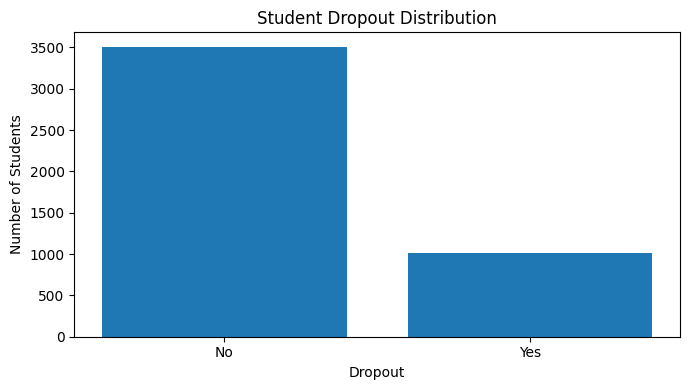


GPA:


,GPA,Dropout,Percent
0,Excellent,No,93.1
1,Excellent,Yes,6.9
2,GPA is not showing yet,No,86.8
3,GPA is not showing yet,Yes,13.2
4,Good,Yes,51.4
5,Good,No,48.6
6,Pass,Yes,59.4
7,Pass,No,40.6
8,Very Good,No,82.2
9,Very Good,Yes,17.8



Employment Status:


,Employment Status,Dropout,Percent
0,Employed full-time,No,77.0
1,Employed full-time,Yes,23.0
2,Employed part-time,No,64.3
3,Employed part-time,Yes,35.7
4,Own business,Yes,50.3
5,Own business,No,49.7
6,Unemployed,No,83.7
7,Unemployed,Yes,16.3


In [4]:
target_counts = df[target_col].value_counts()

plt.figure(figsize=(7, 4))
plt.bar(
    target_counts.index.astype(str),
    target_counts.values
)
plt.title("Student Dropout Distribution")
plt.xlabel("Dropout")
plt.ylabel("Number of Students")
plt.tight_layout()
plt.show()

# Show the most common values for selected important factors if available
important_names = [
    "GPA",
    "Academic year",
    "Employment status",
    "Family support",
    "Major pre-knowledge"
]

for keyword in important_names:
    matches = [
        c for c in df.columns
        if keyword.lower() in c.lower()
    ]

    if matches:
        c = matches[0]

        print(f"\n{c}:")
        display(
            df.groupby(c)[target_col]
            .value_counts(normalize=True)
            .mul(100)
            .round(1)
            .rename("Percent")
            .reset_index()
            .head(20)
        )


## Step 5 — Prepare X and y


In [5]:
X = df.drop(columns=[target_col]).copy()
y = df[target_col].copy()

# Remove rows where target is missing, if any
valid = y.notna()
X = X.loc[valid].reset_index(drop=True)
y = y.loc[valid].reset_index(drop=True)

print("X shape:", X.shape)
print("y shape:", y.shape)
print("\nClass distribution:")
print(y.value_counts())


X shape: (4522, 25)
y shape: (4522,)

Class distribution:
Dropout
No     3506
Yes    1016
Name: count, dtype: int64


## Step 6 — Train/Test split


In [6]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print("Training rows:", len(X_train))
print("Testing rows:", len(X_test))

print("\nTraining distribution:")
print(y_train.value_counts())

print("\nTesting distribution:")
print(y_test.value_counts())


Training rows: 3617
Testing rows: 905

Training distribution:
Dropout
No     2804
Yes     813
Name: count, dtype: int64

Testing distribution:
Dropout
No     702
Yes    203
Name: count, dtype: int64


## Step 7 — Preprocessing + SMOTE-ENN + models


In [7]:
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline as SkPipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.impute import SimpleImputer

from imblearn.combine import SMOTEENN
from imblearn.pipeline import Pipeline as ImbPipeline

from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.svm import SVC

# Detect numeric and categorical columns
numeric_cols = X_train.select_dtypes(
    include=["number"]
).columns.tolist()

categorical_cols = [
    c for c in X_train.columns
    if c not in numeric_cols
]

print("Numeric columns:", len(numeric_cols))
print("Categorical columns:", len(categorical_cols))

numeric_transformer = SkPipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler())
])

categorical_transformer = SkPipeline([
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("onehot", OneHotEncoder(
        handle_unknown="ignore",
        sparse_output=False
    ))
])

preprocessor = ColumnTransformer([
    ("num", numeric_transformer, numeric_cols),
    ("cat", categorical_transformer, categorical_cols)
])

def make_model_pipeline(model):
    return ImbPipeline([
        ("preprocess", preprocessor),
        ("balance", SMOTEENN(
            sampling_strategy=0.7,
            random_state=42
        )),
        ("model", model)
    ])

logistic_model = make_model_pipeline(
    LogisticRegression(
        max_iter=3000,
        random_state=42
    )
)

forest_model = make_model_pipeline(
    RandomForestClassifier(
        n_estimators=300,
        random_state=42,
        n_jobs=-1
    )
)

svm_model = make_model_pipeline(
    SVC(
        kernel="rbf",
        random_state=42
    )
)


Numeric columns: 0
Categorical columns: 25


## Step 8 — Initial 5-fold cross-validation


In [8]:
from sklearn.model_selection import StratifiedKFold, cross_validate

cv = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

models = {
    "Logistic Regression": logistic_model,
    "Random Forest": forest_model,
    "SVM": svm_model
}

rows = []

for name, model in models.items():
    scores = cross_validate(
        model,
        X_train,
        y_train,
        cv=cv,
        scoring=["accuracy", "f1_macro"],
        n_jobs=-1
    )

    rows.append({
        "Model": name,
        "CV Accuracy (%)": round(
            scores["test_accuracy"].mean() * 100, 2
        ),
        "CV Macro F1": round(
            scores["test_f1_macro"].mean(), 3
        )
    })

cv_results = pd.DataFrame(rows).sort_values(
    "CV Macro F1",
    ascending=False
)

display(cv_results)


,Model,CV Accuracy (%),CV Macro F1
1,Random Forest,85.35,0.792
2,SVM,83.52,0.782
0,Logistic Regression,79.98,0.753


## Step 9 — Hyperparameter tuning


In [9]:
from sklearn.model_selection import GridSearchCV

logistic_grid = GridSearchCV(
    logistic_model,
    param_grid={
        "model__C": [0.1, 1, 10],
        "model__class_weight": [None, "balanced"]
    },
    cv=cv,
    scoring={
        "accuracy": "accuracy",
        "f1_macro": "f1_macro"
    },
    refit="f1_macro",
    n_jobs=-1
)

forest_grid = GridSearchCV(
    forest_model,
    param_grid={
        "model__n_estimators": [300, 500],
        "model__max_depth": [8, 15, None],
        "model__min_samples_leaf": [1, 2, 4],
        "model__max_features": ["sqrt", "log2"],
        "model__class_weight": [None, "balanced"]
    },
    cv=cv,
    scoring={
        "accuracy": "accuracy",
        "f1_macro": "f1_macro"
    },
    refit="f1_macro",
    n_jobs=-1
)

svm_grid = GridSearchCV(
    svm_model,
    param_grid={
        "model__C": [0.1, 1, 10],
        "model__gamma": ["scale", 0.01, 0.1],
        "model__class_weight": [None, "balanced"]
    },
    cv=cv,
    scoring={
        "accuracy": "accuracy",
        "f1_macro": "f1_macro"
    },
    refit="f1_macro",
    n_jobs=-1
)

logistic_grid.fit(X_train, y_train)
forest_grid.fit(X_train, y_train)
svm_grid.fit(X_train, y_train)

tuned_models = {
    "Logistic Regression": logistic_grid,
    "Random Forest": forest_grid,
    "SVM": svm_grid
}

tuned_rows = []

for name, grid in tuned_models.items():
    best_i = grid.best_index_

    tuned_rows.append({
        "Model": name,
        "Best CV Accuracy (%)": round(
            grid.cv_results_["mean_test_accuracy"][best_i] * 100,
            2
        ),
        "Best CV Macro F1": round(
            grid.cv_results_["mean_test_f1_macro"][best_i],
            3
        )
    })

tuned_results = pd.DataFrame(
    tuned_rows
).sort_values(
    "Best CV Macro F1",
    ascending=False
)

display(tuned_results)

print("\nBest Logistic settings:")
print(logistic_grid.best_params_)

print("\nBest Random Forest settings:")
print(forest_grid.best_params_)

print("\nBest SVM settings:")
print(svm_grid.best_params_)


,Model,Best CV Accuracy (%),Best CV Macro F1
1,Random Forest,85.51,0.793
2,SVM,83.83,0.783
0,Logistic Regression,80.18,0.754



Best Logistic settings:
{'model__C': 10, 'model__class_weight': 'balanced'}

Best Random Forest settings:
{'model__class_weight': None, 'model__max_depth': 15, 'model__max_features': 'sqrt', 'model__min_samples_leaf': 1, 'model__n_estimators': 500}

Best SVM settings:
{'model__C': 1, 'model__class_weight': 'balanced', 'model__gamma': 0.1}


## Step 10 — Select the best model using CV, then test once


Selected Model: Random Forest
Test Accuracy: 83.54 %
Test Macro F1: 0.759

Classification Report:
              precision    recall  f1-score   support

          No       0.89      0.90      0.89       702
         Yes       0.64      0.61      0.62       203

    accuracy                           0.84       905
   macro avg       0.76      0.75      0.76       905
weighted avg       0.83      0.84      0.83       905



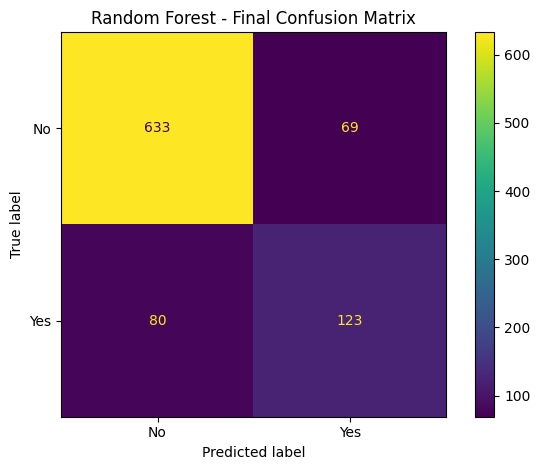

In [10]:
from sklearn.metrics import (
    accuracy_score,
    f1_score,
    classification_report,
    ConfusionMatrixDisplay
)

best_model_name = max(
    tuned_models,
    key=lambda name: tuned_models[name].best_score_
)

best_model = tuned_models[
    best_model_name
].best_estimator_

test_predictions = best_model.predict(X_test)

test_accuracy = accuracy_score(
    y_test,
    test_predictions
)

test_macro_f1 = f1_score(
    y_test,
    test_predictions,
    average="macro"
)

print("Selected Model:", best_model_name)
print(
    "Test Accuracy:",
    round(test_accuracy * 100, 2),
    "%"
)
print(
    "Test Macro F1:",
    round(test_macro_f1, 3)
)

print("\nClassification Report:")
print(
    classification_report(
        y_test,
        test_predictions,
        zero_division=0
    )
)

ConfusionMatrixDisplay.from_predictions(
    y_test,
    test_predictions
)

plt.title(
    best_model_name +
    " - Final Confusion Matrix"
)
plt.tight_layout()
plt.show()


## Step 11 — Feature importance


Top 10 important original features:


,Feature,Importance
4,Year,0.023172
8,GPA,0.022080
22,Family/Friends Support,0.015236
9,Failed Courses,0.014476
6,Faculty Name,0.013512
5,University Name,0.011151
17,Family/Employer Pressure,0.010301
15,Major Preknowledge,0.009858
1,Age,0.008814
18,Cultural Expectation,0.007900


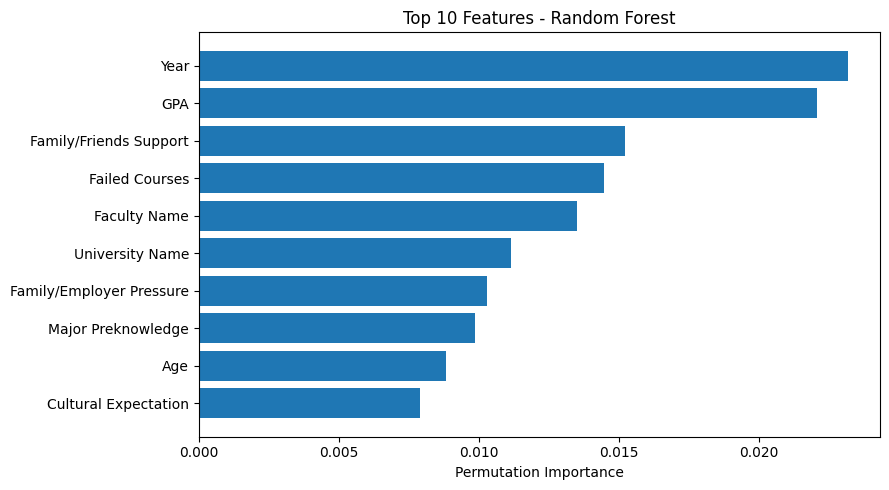

In [11]:
from sklearn.inspection import permutation_importance

importance = permutation_importance(
    best_model,
    X_test,
    y_test,
    scoring="f1_macro",
    n_repeats=5,
    random_state=42,
    n_jobs=-1
)

feature_importance = pd.DataFrame({
    "Feature": X.columns,
    "Importance": importance.importances_mean
}).sort_values(
    "Importance",
    ascending=False
)

print("Top 10 important original features:")
display(feature_importance.head(10))

top10 = (
    feature_importance
    .head(10)
    .sort_values("Importance")
)

plt.figure(figsize=(9, 5))
plt.barh(
    top10["Feature"],
    top10["Importance"]
)
plt.title(
    "Top 10 Features - " +
    best_model_name
)
plt.xlabel("Permutation Importance")
plt.tight_layout()
plt.show()


## Step 12 — Final summary


In [12]:
final_results = pd.DataFrame({
    "Selected Model": [best_model_name],
    "Test Accuracy (%)": [
        round(test_accuracy * 100, 2)
    ],
    "Test Macro F1": [
        round(test_macro_f1, 3)
    ]
})

print("FINAL RESULTS")
display(final_results)

if test_accuracy >= 0.80:
    print("Accuracy requirement reached: >= 80%")
else:
    print("Accuracy is below 80%. Do not change the test set or add target-leaking features.")


FINAL RESULTS


,Selected Model,Test Accuracy (%),Test Macro F1
0,Random Forest,83.54,0.759


Accuracy requirement reached: >= 80%
